### Project Proposal: Statistical Analysis of Changing-Look AGN Candidates

For my final project, I plan to use multi-epoch spectroscopic data from the Sloan Digital Sky Survey (SDSS) that I collected for my undergraduate research on changing-look active galactic nuclei (CLAGN). My research involves identifying AGN that undergo substantial changes in their optical or ultraviolet spectra, particularly changes in broad emission lines.

I have already assembled a sample of AGN with multiple spectroscopic observations, including previously identified CLAGN and additional candidates. For this project, I would like to investigate whether the changes in their emission-line fluxes are statistically significant.

I plan to begin by examining the spectra of a few known CLAGN and measuring the flux of a selected broad emission line across different observation epochs. I will then use the measurement uncertainties to evaluate the significance of these changes and compare the results with other candidate objects.

My initial goal is to develop a statistical method for distinguishing significant emission-line variability from changes that could arise from measurement uncertainty. Depending on the results, I may expand the analysis to additional candidates and investigate potential sources of systematic error.

For my initial plot, I will use existing SDSS spectra to compare the selected emission-line region across two observation epochs for a known CLAGN.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from astropy.io import fits

df = pd.read_csv(
    "clagn_130_candidates_full_data.csv"
)

targets = (
    df.groupby("gaia_source_id")
      .agg(
          z=("z", "median"),
          n_spectra=("filename", "count")
      )
      .reset_index()
)

print(f"Total spectra: {len(df):,}")
print(f"Unique candidates: {len(targets):,}")

targets.head()

Total spectra: 542
Unique candidates: 130


,gaia_source_id,z,n_spectra
0,4861318863546880,0.691827,3
1,291720810173878144,0.519890,2
2,309581655013247616,0.655849,3
3,581047055822149504,0.516901,2
4,611620935137196032,0.697726,2


In [2]:
def read_spectrum(path):
    with fits.open(path, memmap=False) as hdul:
        data = hdul[1].data

        wave = 10**np.asarray(data["loglam"], dtype=float)
        flux = np.asarray(data["flux"], dtype=float).copy()
        ivar = np.asarray(data["ivar"], dtype=float).copy()

    good = (
        np.isfinite(wave)
        & np.isfinite(flux)
        & (ivar > 0)
    )

    return wave[good], flux[good]

In [3]:
multi_targets = (
    targets[targets["n_spectra"] >= 2]
    .reset_index(drop=True)
)

In [4]:
# Emission lines in Angstroms
emission_lines = [
    ("Lyα",      1215.67),
    ("C IV",     1549.0),
    ("C III]",   1908.7),
    ("Mg II",    2798.0),
    ("[O II]",   3727.0),
    ("Hδ",       4101.7),
    ("Hγ",       4340.5),
    ("Hβ",       4861.3),
    ("[O III]",  4958.9),
    ("[O III]",  5006.8),
    ("Hα",       6562.8),
]


def make_candidate_figure(index, rest_frame=True):

    target = multi_targets.iloc[index]

    gaia_id = target["gaia_source_id"]
    z = target["z"]

    spectra = df[
        df["gaia_source_id"] == gaia_id
    ].sort_values("mjd")

    fig, ax = plt.subplots(figsize=(11, 8.5))

    wave_min = np.inf
    wave_max = -np.inf

    for _, row in spectra.iterrows():

        wave, flux = read_spectrum(row["local_path"])

        if rest_frame:
            wave = wave / (1 + z)

        wave_min = min(wave_min, np.nanmin(wave))
        wave_max = max(wave_max, np.nanmax(wave))

        ax.plot(
            wave,
            flux,
            lw=1,
            alpha=0.7,
            label=f"MJD {row['mjd']}",
        )

    # Emission-line markers
    for line_name, rest_wave in emission_lines:

        if rest_frame:
            line_wave = rest_wave
        else:
            line_wave = rest_wave * (1 + z)

        if wave_min <= line_wave <= wave_max:

            ax.axvline(
                line_wave,
                linestyle="--",
                linewidth=1,
                alpha=0.4
            )

            ax.text(
                line_wave,
                0.97,
                line_name,
                rotation=90,
                transform=ax.get_xaxis_transform(),
                ha="right",
                va="top",
                fontsize=9,
                alpha=0.75
            )

    if rest_frame:
        ax.set_xlabel("Rest-frame wavelength (Å)")
    else:
        ax.set_xlabel("Observed wavelength (Å)")

    ax.set_ylabel(
        r"Flux ($10^{-17}$ erg s$^{-1}$ cm$^{-2}$ Å$^{-1}$)"
    )

    ax.set_title(
        f"Gaia {int(gaia_id)}   |   "
        f"z = {z:.3f}   |   "
        f"{len(spectra)} spectra"
    )

    if len(spectra) <= 12:
        ax.legend(fontsize=8)
    else:
        ax.text(
            0.99,
            0.98,
            f"MJD {spectra['mjd'].min()}–{spectra['mjd'].max()}",
            transform=ax.transAxes,
            ha="right",
            va="top",
            fontsize=9
        )

    ax.grid(alpha=0.2)


def plot_candidate(index, rest_frame=True):

    fig = make_candidate_figure(
        index,
        rest_frame=rest_frame
    )

    plt.show()

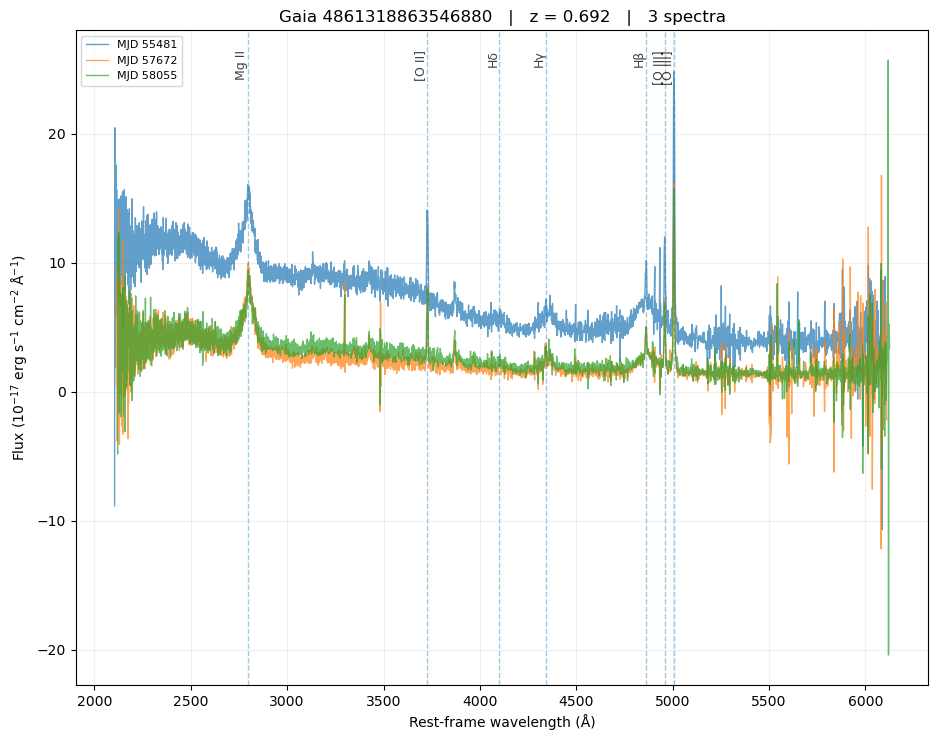

In [5]:
plot_candidate(0) # Candidates range from 0-129